In [1]:
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import transforms
from tqdm.notebook import tnrange, tqdm_notebook
from pytorch_lightning.loggers import CSVLogger
import pytorch_lightning as pl
import torch.nn as nn
import torch

import os
import cv2
import matplotlib.pyplot as plt
import pandas as pd
import sys
import numpy as np

from models.resnets import ResNetAutoencoder
from models.trainer import LitAutoencoder
from dataset import AEDataset

sys.path.append("../_Segmentation Model/")
sys.path.append("../")

import utils
from transforms import MaskResize, InstanceMaskCropper, PadToSizeTensor, MinMaxNormalize

In [2]:
image_data = pd.read_csv('image_data.csv')

In [3]:
trans = transforms.Compose([
    transforms.ToTensor(),
    # PadToSizeTensor(3500, 3500),
    transforms.Resize(size=(512, 512)),
    MinMaxNormalize()
])

utils.set_seed()
batch_size = 16
all_dataset = AEDataset(image_data, 250, trans)
all_dataset.image_data = all_dataset.image_data[all_dataset.image_data['version'] == '_separated']
train_set, val_set, test_set = random_split(all_dataset, [0.7, 0.2, 0.1])

print(f'Train Set: {len(train_set)}')
print(f'Validation Set: {len(val_set)}')
print(f'Test Set: {len(test_set)}')

train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False)

Train Set: 816
Validation Set: 233
Test Set: 116


In [4]:
from pytorch_lightning.callbacks import (
    ModelCheckpoint,
    LearningRateMonitor,
    EarlyStopping,
)

In [5]:
def build_trainer(
        max_epochs=30,
        monitor_metric="val/mse_epoch",
        save_top_k=3,
        early_stop_patience=5,
        default_root_dir="runs/",
        gradient_clip_val=1.0,
    ):
    
    # -----------------------
    # Callbacks
    # -----------------------

    # Save best checkpoints based on validation MSE
    checkpoint_callback = ModelCheckpoint(
        monitor=monitor_metric,
        filename="autoencoder-{epoch:02d}-{val_mse:.4f}",
        save_top_k=save_top_k,
        mode="min",
        save_last=True,
    )

    # Stop early if validation stops improving
    early_stop = EarlyStopping(
        monitor=monitor_metric,
        patience=early_stop_patience,
        mode="min",
        verbose=True
    )

    # Log learning rate each epoch
    lr_monitor = LearningRateMonitor(logging_interval="epoch")

    # -----------------------
    # Logger
    # -----------------------
    csv_logger = CSVLogger(
        save_dir=default_root_dir,
        name="autoencoder_logs"
    )

    # -----------------------
    # Trainer Instance
    # -----------------------
    trainer = pl.Trainer(
        max_epochs=max_epochs,
        accelerator="gpu" if torch.cuda.is_available() else "cpu",
        devices=1,
        logger=csv_logger,
        callbacks=[checkpoint_callback, early_stop, lr_monitor],
        gradient_clip_val=gradient_clip_val,
        deterministic=True,
        log_every_n_steps=10,
        enable_progress_bar=True,
    )

    return trainer

In [6]:
arch = ResNetAutoencoder(model_name='resnet34', pretrained=False)
model = LitAutoencoder(arch, lr=1e-4)

trainer = build_trainer(
    max_epochs=30,
    monitor_metric="val/mse_epoch",
    save_top_k=3,
    early_stop_patience=8,
    default_root_dir="results/"
)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


You are using a CUDA device ('NVIDIA GeForce RTX 4060 Laptop GPU') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name      | Type              | Params | Mode 
--------------------------------------------------------
0 | model     | ResNetAutoencoder | 23.0 M | train
1 | loss_fn   | MSELoss           | 0      | train
2 | train_mse | MeanMetric        | 0      | train
3 | val_mse   | MeanMetric        | 0      | train
--------------------------------------------------------
23.0 M    Trainable params
0         Non-trainable params
23.0 M    Total params
92.100    Total estimated model params size (MB)
136       Modules in train mode
0         Modules in eval mode


Sanity Checking: |                                                                               | 0/? [00:00<…

C:\Users\Brian\anaconda3\envs\dl_env\lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:425: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=21` in the `DataLoader` to improve performance.
C:\Users\Brian\anaconda3\envs\dl_env\lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:425: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=21` in the `DataLoader` to improve performance.


Training: |                                                                                      | 0/? [00:00<…

Validation: |                                                                                    | 0/? [00:00<…

Metric val/mse_epoch improved. New best score: 0.082


Validation: |                                                                                    | 0/? [00:00<…

Metric val/mse_epoch improved by 0.028 >= min_delta = 0.0. New best score: 0.053


Validation: |                                                                                    | 0/? [00:00<…

Metric val/mse_epoch improved by 0.011 >= min_delta = 0.0. New best score: 0.042


Validation: |                                                                                    | 0/? [00:00<…

Metric val/mse_epoch improved by 0.006 >= min_delta = 0.0. New best score: 0.037


Validation: |                                                                                    | 0/? [00:00<…

Metric val/mse_epoch improved by 0.005 >= min_delta = 0.0. New best score: 0.032


Validation: |                                                                                    | 0/? [00:00<…

Metric val/mse_epoch improved by 0.003 >= min_delta = 0.0. New best score: 0.029


Validation: |                                                                                    | 0/? [00:00<…

Metric val/mse_epoch improved by 0.003 >= min_delta = 0.0. New best score: 0.026


Validation: |                                                                                    | 0/? [00:00<…

Metric val/mse_epoch improved by 0.002 >= min_delta = 0.0. New best score: 0.024


Validation: |                                                                                    | 0/? [00:00<…

Metric val/mse_epoch improved by 0.001 >= min_delta = 0.0. New best score: 0.023


Validation: |                                                                                    | 0/? [00:00<…

Metric val/mse_epoch improved by 0.001 >= min_delta = 0.0. New best score: 0.022


Validation: |                                                                                    | 0/? [00:00<…

Metric val/mse_epoch improved by 0.000 >= min_delta = 0.0. New best score: 0.022


Validation: |                                                                                    | 0/? [00:00<…

Metric val/mse_epoch improved by 0.001 >= min_delta = 0.0. New best score: 0.020


Validation: |                                                                                    | 0/? [00:00<…

Metric val/mse_epoch improved by 0.001 >= min_delta = 0.0. New best score: 0.020


Validation: |                                                                                    | 0/? [00:00<…

Metric val/mse_epoch improved by 0.001 >= min_delta = 0.0. New best score: 0.018


Validation: |                                                                                    | 0/? [00:00<…

Metric val/mse_epoch improved by 0.000 >= min_delta = 0.0. New best score: 0.018


Validation: |                                                                                    | 0/? [00:00<…

Metric val/mse_epoch improved by 0.001 >= min_delta = 0.0. New best score: 0.018


Validation: |                                                                                    | 0/? [00:00<…

Metric val/mse_epoch improved by 0.000 >= min_delta = 0.0. New best score: 0.017


Validation: |                                                                                    | 0/? [00:00<…

Metric val/mse_epoch improved by 0.001 >= min_delta = 0.0. New best score: 0.017


Validation: |                                                                                    | 0/? [00:00<…

C:\Users\Brian\Desktop\InstructionalMaterials\DS414_Capstone\Intreeligent\_Autoencoder\visualize.py:66: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(1, figsize=(10, 10))
Metric val/mse_epoch improved by 0.000 >= min_delta = 0.0. New best score: 0.017


Validation: |                                                                                    | 0/? [00:00<…

C:\Users\Brian\Desktop\InstructionalMaterials\DS414_Capstone\Intreeligent\_Autoencoder\visualize.py:35: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axs = plt.subplots(self.m, self.n, figsize=self.figsize)
Metric val/mse_epoch improved by 0.000 >= min_delta = 0.0. New best score: 0.016


Validation: |                                                                                    | 0/? [00:00<…

Metric val/mse_epoch improved by 0.000 >= min_delta = 0.0. New best score: 0.016


Validation: |                                                                                    | 0/? [00:00<…

Metric val/mse_epoch improved by 0.000 >= min_delta = 0.0. New best score: 0.016


Validation: |                                                                                    | 0/? [00:00<…

Metric val/mse_epoch improved by 0.000 >= min_delta = 0.0. New best score: 0.015


Validation: |                                                                                    | 0/? [00:00<…

Metric val/mse_epoch improved by 0.000 >= min_delta = 0.0. New best score: 0.015


Validation: |                                                                                    | 0/? [00:00<…

Metric val/mse_epoch improved by 0.000 >= min_delta = 0.0. New best score: 0.015


Validation: |                                                                                    | 0/? [00:00<…

Metric val/mse_epoch improved by 0.000 >= min_delta = 0.0. New best score: 0.015


Validation: |                                                                                    | 0/? [00:00<…

Metric val/mse_epoch improved by 0.000 >= min_delta = 0.0. New best score: 0.015


Validation: |                                                                                    | 0/? [00:00<…

Validation: |                                                                                    | 0/? [00:00<…

Metric val/mse_epoch improved by 0.000 >= min_delta = 0.0. New best score: 0.014


Validation: |                                                                                    | 0/? [00:00<…

Metric val/mse_epoch improved by 0.000 >= min_delta = 0.0. New best score: 0.014
`Trainer.fit` stopped: `max_epochs=30` reached.


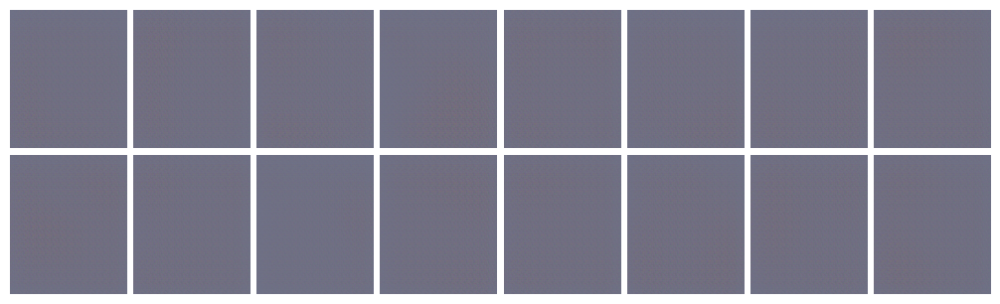

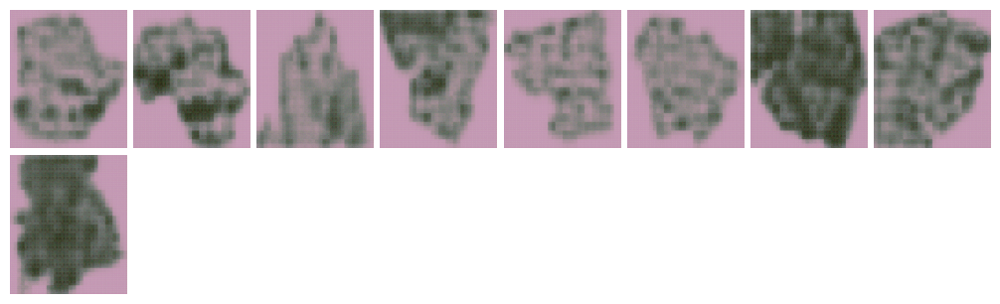

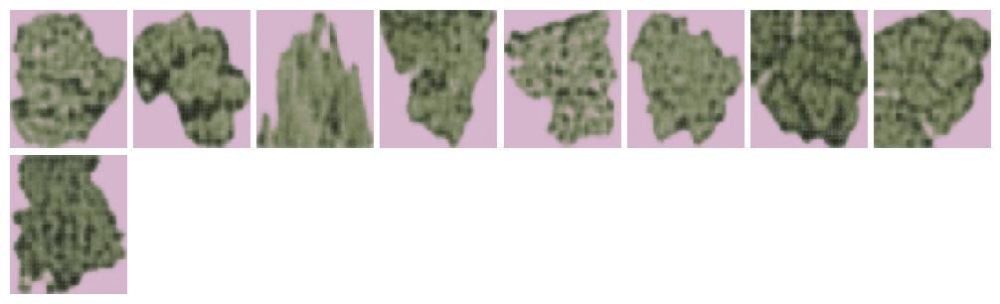

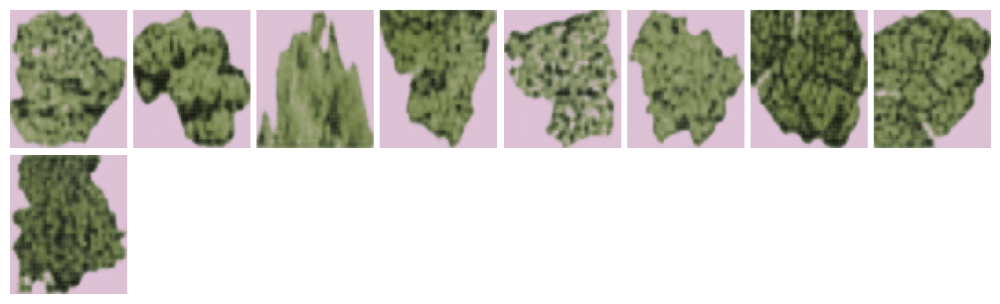

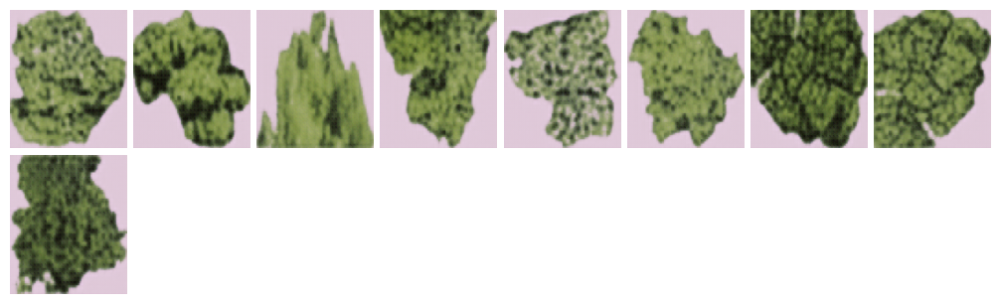

...

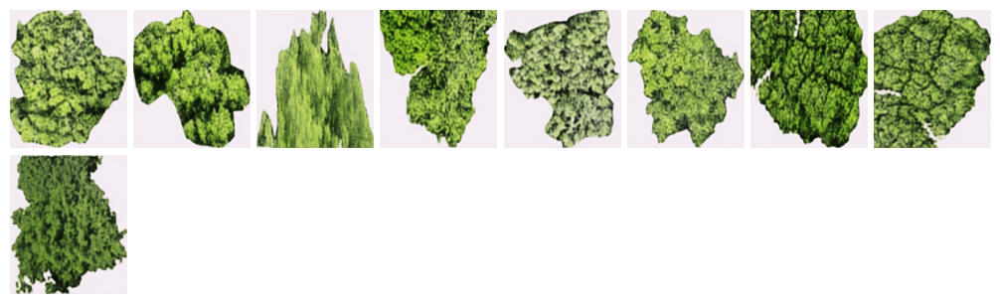

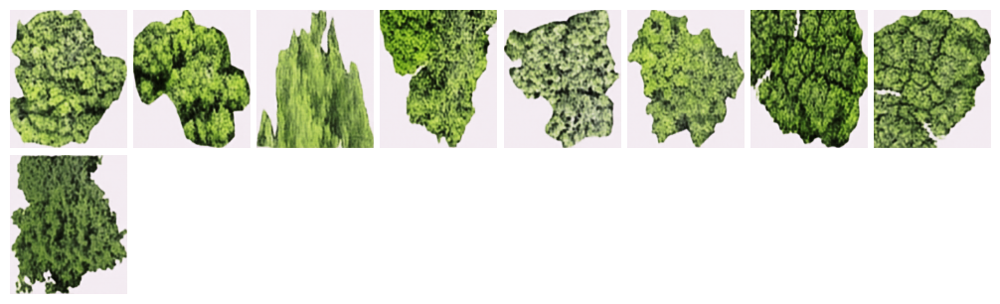

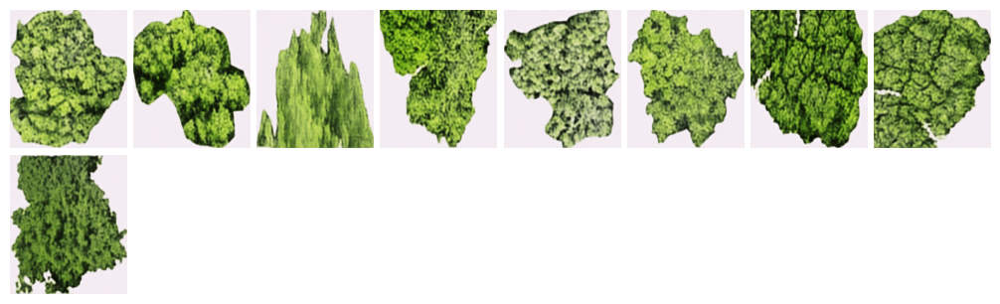

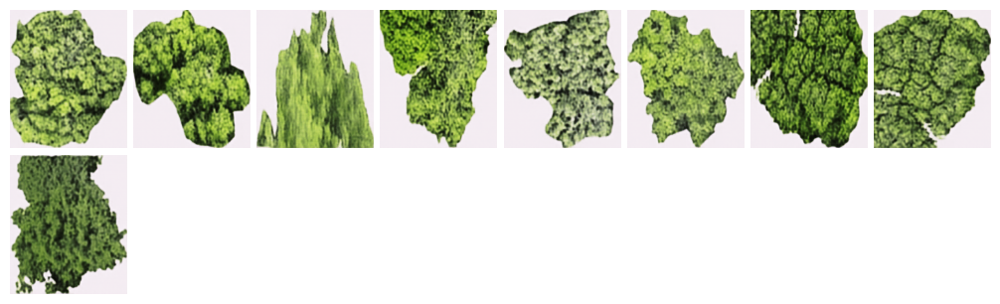

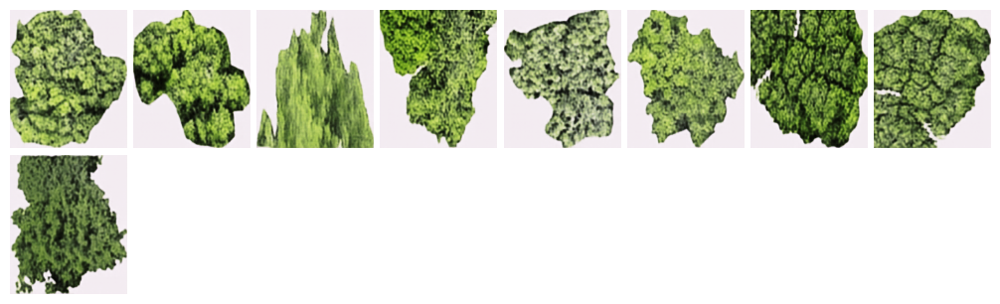

In [7]:
trainer.fit(model, train_loader, val_loader)